<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Centre un titre</title>
    <style>
        h1 {
            text-align: center;
        }
    </style>
</head>

<h1 align:center>  Breast Cancer: Causes and Drug Target Prediction </h1>

The program analyzes the cause of breast cancer from a Boolean network datamodel, namely which genes should be mutated to cause cancer and are they oncogenes (True) or tumor suppressors (False).
Next, the program found the potential therapeutic targets and the actions on them for a cancer caused by BRCA1 mutation.

In [1]:
import time
import matplotlib.pyplot as plt
from sympy import SOPform, simplify_logic
from tabulate import tabulate
from pulp import PULP_CBC_CMD
from boon import *

## Network model
import the network model from a text file or a boon file.
In a normal cell, two phenotypes exist potentially: the apoptosis and the cell division.
The model is a Boolean network connecting genes involved in Beast cancer.

In [2]:
bcbn = BooN.load("breast-cancer")
print(bcbn)

Bax = p53 ∧ ¬Bcl2
ERK12 = EGFR
PIK3CA = EGFR ∧ ¬PTEN
BRCA1 = ¬CycD1
PTEN = p53
Akt = PIK3CA
PARP1 = ERK12
EGFR = ¬BRCA1
GSK3 = ¬Akt
Bcl2 = Akt
CycD1 = (ERK12 ∧ ¬GSK3) ∨ (PARP1 ∧ ¬BRCA1)
MDM2 = Akt ∧ p53
p53 = (BRCA1 ∧ ¬MDM2) ∨ (¬MDM2 ∧ ¬PARP1)


### List of genes

In [3]:
print(bcbn.variables)

{Bax, ERK12, PIK3CA, BRCA1, PTEN, Akt, PARP1, EGFR, GSK3, Bcl2, CycD1, MDM2, p53}


### Interaction Graph

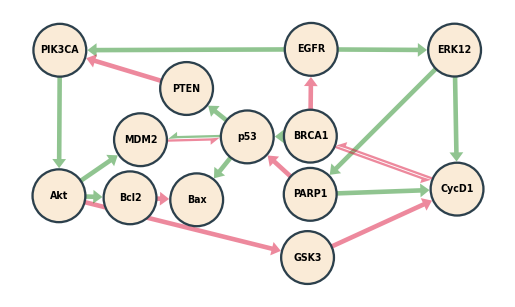

In [4]:
bcbn.draw_IG()
plt.show()  # Show the interaction graph

### Stable States
In this model, two stable states exist that respectively correspond to cell division and apoptosis, identified by the Boolean version of the biomarker states.

In [5]:
stable_states = bcbn.stable_states
print(tabulate(stable_states, headers='keys', tablefmt='grid'))

+---------+---------+----------+--------+--------+-------+--------+-------+--------+---------+--------+-------+---------+
| CycD1   | PARP1   | PIK3CA   | PTEN   | GSK3   | Bax   | EGFR   | Akt   | Bcl2   | BRCA1   | MDM2   | p53   | ERK12   |
+=========+=========+==========+========+========+=======+========+=======+========+=========+========+=======+=========+
| False   | False   | False    | True   | True   | True  | False  | False | False  | True    | False  | True  | False   |
+---------+---------+----------+--------+--------+-------+--------+-------+--------+---------+--------+-------+---------+
| True    | True    | True     | False  | False  | False | True   | True  | True   | False   | False  | False | True    |
+---------+---------+----------+--------+--------+-------+--------+-------+--------+---------+--------+-------+---------+


## Cause of Cancer
Firstly, to identify the potential causes of cancer, a controllability analysis is applied.
This analysis is based on the characterization of biomarkers, which are genes whose states are used to differentiate between phenotypes.
These biomarkers are CycD1 and Bax
Based on the states of the aforementioned biomarkers. A control query is then defined with the goal of identifying the cause of cancer.

### Characterization of the biomarkers
The selected biomarkers are CycD1 and Bax. The Boolean profiles, respectively, correspond to cell division and apoptosis.


| CyCD1 | Bax |     *Phenotype* |
|:-----:|:---:|----------------:|
|   0   |  1  |     *Apoptosis* |
|   1   |  0  | *Cell Division* |


In [6]:
CycD1, Bax = symbols("CycD1 Bax")
biomarkers = {CycD1, Bax}

In essence, the model characterizes the cancerous state as a loss of apoptosis, which is a hallmark of cancer.
We will define a query or formula that delineates the circumstances under which the apoptosis cannot be sustained in any stable state.

In [7]:
# Characterize a marking corresponding to the apoptosis
marking = {CycD1: False, Bax: True}
# convert the marking into a formula
apoptosis_marking = SOPform(biomarkers, [marking])
print("Apoptosis biomarkers")
print(tabulate([marking], headers='keys', tablefmt='plain'))

Apoptosis biomarkers
CycD1    Bax
False    True



### Control query definition
Set the marking formula of cancer losing the apoptosis, that is the negation of apoptosis query. A cell therefore cannot die anymore defining a hallmark of cancer.

In [8]:
kquery = simplify_logic(~apoptosis_marking, force=True)
print("Disease query, prevent apoptosis: ", kquery)

Disease query, prevent apoptosis:  CycD1 | ~Bax


Now, we define the variables where the control can be applied to force the freeze of variables.
A variable can have two controls for freezing to True and to False.
The biomarkers are always excluded from the control since they are observers characterizing the phenotypes by their profile.

In [9]:
frozenvars0 = frozenvars1 = bcbn.variables - biomarkers  # All variables but biomarkers
print("Frozen variables 0 and 1")
print(tabulate([frozenvars0, frozenvars1], tablefmt='fancy_grid', showindex=True))

Frozen variables 0 and 1
╒═══╤═══════╤════════╤═══════╤══════╤═════╤═══════╤══════╤══════╤══════╤══════╤═════╕
│ 0 │ ERK12 │ PIK3CA │ BRCA1 │ PTEN │ Akt │ PARP1 │ EGFR │ GSK3 │ Bcl2 │ MDM2 │ p53 │
├───┼───────┼────────┼───────┼──────┼─────┼───────┼──────┼──────┼──────┼──────┼─────┤
│ 1 │ ERK12 │ PIK3CA │ BRCA1 │ PTEN │ Akt │ PARP1 │ EGFR │ GSK3 │ Bcl2 │ MDM2 │ p53 │
╘═══╧═══════╧════════╧═══════╧══════╧═════╧═══════╧══════╧══════╧══════╧══════╧═════╛


### Boolean Controlled Network (BCN)
Copy the network and fix the control on it. The control consists in adding control parameters such that: 
- _u0X: is the control for setting the variable X to False
- _u1X: is the control for setting the variable X to True.

A control is active when it freezes (set to 0/False). 


In [10]:
bcc = bcbn.copy()
bcc.control(frozenvars0, frozenvars1)
print(bcc)

Bax = p53 ∧ ¬Bcl2
ERK12 = ¬_u1ERK12 ∨ (EGFR ∧ _u0ERK12)
PIK3CA = ¬_u1PIK3CA ∨ (EGFR ∧ _u0PIK3CA ∧ ¬PTEN)
BRCA1 = ¬_u1BRCA1 ∨ (_u0BRCA1 ∧ ¬CycD1)
PTEN = ¬_u1PTEN ∨ (_u0PTEN ∧ p53)
Akt = ¬_u1Akt ∨ (PIK3CA ∧ _u0Akt)
PARP1 = ¬_u1PARP1 ∨ (ERK12 ∧ _u0PARP1)
EGFR = ¬_u1EGFR ∨ (_u0EGFR ∧ ¬BRCA1)
GSK3 = ¬_u1GSK3 ∨ (_u0GSK3 ∧ ¬Akt)
Bcl2 = ¬_u1Bcl2 ∨ (Akt ∧ _u0Bcl2)
CycD1 = (ERK12 ∧ ¬GSK3) ∨ (PARP1 ∧ ¬BRCA1)
MDM2 = ¬_u1MDM2 ∨ (Akt ∧ _u0MDM2 ∧ p53)
p53 = ¬_u1p53 ∨ (_u0p53 ∧ ((BRCA1 ∧ ¬MDM2) ∨ (¬MDM2 ∧ ¬PARP1)))


 ### Controllability Analysis
A controllability analysis should be conducted for identifying the potential gene freezes that would satisfy the query at stable state.

The number of models is approximately 3,500. We kindly request your patience.

#### Necessity
The query is: *"Necessary avoid the apoptosis"*

In [11]:
start_time = time.time()
 # The trace is activated to see the evolution of the computation.
destiny = bcc.necessary(kquery, trace=True) 
print("Runtime..: {:5.2f}".format(time.time() - start_time))
print("# clauses: {}".format(len(destiny.args)))
print("# symbols: {}".format(destiny.count(Symbol)))

BooN CNF >> # SAT models:[ 3452]
BooN CNF >> CNF formatting: 100% |██████████████████[3452  - 00:07 - 473.48it/s]
Runtime..: 21.53
# clauses: 3452
# symbols: 53507


#### Controllability Analysis
About 10 solutions

In [12]:
print("\nCore computation")
# Compute the core.
start_time = time.time()
# The standard Pulp solver (Default) is used. However, other solvers as GUROBI can be used for improving the performance of the resolution.
core = bcc.destify(destiny, trace=True, solver=PULP_CBC_CMD)
print("Runtime: {:5.2f}".format(time.time() - start_time))


Core computation
BooN PI >> # solutions:[  9]                           
Runtime:  6.61


In [13]:
print("\n",tabulate(core, headers=['Control'], tablefmt='plain', showindex=True))


                Control
 0  _u1EGFR    _u0GSK3
 1  _u1MDM2
 2  _u1Akt
 3  _u1ERK12   _u0GSK3
 4  _u0p53
 5  _u1PIK3CA
 6  _u0BRCA1
 7  _u1Bcl2
 8  _u1EGFR    _u0PTEN


From the core, we derive the potential freeze actions as a pair (gene, freeze action).
The table comprises a series of lines, each corresponding to a specific freeze action on genes that is necessary to fulfil the query.
In the event that two pairs are present within a single line, it is necessary to combine both actions.

In [14]:
print("\nActions")  # Transform the core into actions.
actions = core2actions(core)
print(tabulate(actions))


Actions
--------------  -------------
(MDM2, True)
(Akt, True)
(p53, False)
(PIK3CA, True)
(BRCA1, False)
(Bcl2, True)
(EGFR, True)    (GSK3, False)
(ERK12, True)   (GSK3, False)
(EGFR, True)    (PTEN, False)
--------------  -------------


#### Possibility
The possibility is introduced to show the difference with the necessity. It is important to note that the calculation of the possibility itself results in an empty set of controls,
since an equilibrium already exists which does not correspond to the apoptosis profile.
Consequently, no control is required.

In [15]:
destiny2 = bcc.possibly(kquery)
print("# clauses: {}".format(len(destiny2.args)))
print("# symbols: {}".format(destiny.count(Symbol)))

# clauses: 14
# symbols: 53507


In [16]:
core2 = bcc.destify(destiny2)
print("\nCore")
print(tabulate(map(lambda c: {"no control"} if c==frozenset() else c,core2),headers=['Control'],tablefmt='plain'))


Core
Control
no control


 ## Drug Target identification
We now identify the possible drug target associated with the expected action to cure BRCA1 Cancer.  We define a situation of cancer with BRCA1 knock out mutation.

In [17]:
print("\n" * 2, " - Mutate BRCA1  -")
BRCA1 = symbols("BRCA1")
bcbn.desc[BRCA1] = False
print(bcbn)



  - Mutate BRCA1  -
Bax = p53 ∧ ¬Bcl2
ERK12 = EGFR
PIK3CA = EGFR ∧ ¬PTEN
BRCA1 = false
PTEN = p53
Akt = PIK3CA
PARP1 = ERK12
EGFR = ¬BRCA1
GSK3 = ¬Akt
Bcl2 = Akt
CycD1 = (ERK12 ∧ ¬GSK3) ∨ (PARP1 ∧ ¬BRCA1)
MDM2 = Akt ∧ p53
p53 = (BRCA1 ∧ ¬MDM2) ∨ (¬MDM2 ∧ ¬PARP1)


Define the frozen variables from the previous situation of the frozen variables by removing BRCA1

In [18]:
# copy the network and apply control
# Remove the mutated gene from the controlled variable since no modifications is possible.
frozenvars0 = frozenvars1 = frozenvars0 - {BRCA1}
bndrug = bcbn.copy()  # fix control on a new instance of bcbn.
bndrug.control(frozenvars0, frozenvars1)
print(bndrug)

Bax = p53 ∧ ¬Bcl2
ERK12 = ¬_u1ERK12 ∨ (EGFR ∧ _u0ERK12)
PIK3CA = ¬_u1PIK3CA ∨ (EGFR ∧ _u0PIK3CA ∧ ¬PTEN)
BRCA1 = false
PTEN = ¬_u1PTEN ∨ (_u0PTEN ∧ p53)
Akt = ¬_u1Akt ∨ (PIK3CA ∧ _u0Akt)
PARP1 = ¬_u1PARP1 ∨ (ERK12 ∧ _u0PARP1)
EGFR = ¬_u1EGFR ∨ (_u0EGFR ∧ ¬BRCA1)
GSK3 = ¬_u1GSK3 ∨ (_u0GSK3 ∧ ¬Akt)
Bcl2 = ¬_u1Bcl2 ∨ (Akt ∧ _u0Bcl2)
CycD1 = (ERK12 ∧ ¬GSK3) ∨ (PARP1 ∧ ¬BRCA1)
MDM2 = ¬_u1MDM2 ∨ (Akt ∧ _u0MDM2 ∧ p53)
p53 = ¬_u1p53 ∨ (_u0p53 ∧ ((BRCA1 ∧ ¬MDM2) ∨ (¬MDM2 ∧ ¬PARP1)))


### Controllability analysis
The issue is to identify the actions that induce apoptosis to determine the most effective therapeutic targets.
It is hypothesized that at least a stable state will fulfil the query property since the drug may not work for all people.

Note that the possibility of resolution is faster than the necessity.

#### Possibility

In [19]:
print("\nQuery : Possibly lead to apoptosis.")
start_time = time.time()
destiny = bndrug.possibly(apoptosis_marking)
print("Runtime..: {:5.2f}".format(time.time() - start_time))
print("# clauses: {}".format(len(destiny.args)))
print("# symbols: {}".format(destiny.count(Symbol)))


Query : Possibly lead to apoptosis.
Runtime..:  0.00
# clauses: 15
# symbols: 56


#### Controllability analysis

In [20]:
print("\nCore Computation")
start_time = time.time()
core = bndrug.destify(destiny)
print("Runtime: {:5.2f}".format(time.time() - start_time))
print("\n",tabulate(core, headers=['Control'], tablefmt='plain'))


Core Computation
Runtime:  0.50

 Control
_u0EGFR
_u0ERK12
_u0PARP1


From the core, we finally derive the potential freeze actions to gain the apoptosis.

In [21]:
actions = core2actions(core)
print(tabulate(actions, headers=["Action"]))

Action
--------------
(EGFR, False)
(ERK12, False)
(PARP1, False)


#### Switch to necessary condition
From the solutions, we filter those where the query holds to all stable states corresponding to a necessary condition.

In [22]:
core_necessary = bcbn.filter_necessary(destiny,core,trace=False)
actions = core2actions(core_necessary)
print(tabulate(actions, headers=["Necessary Actions"]))

Necessary Actions
-------------------
(EGFR, False)
(ERK12, False)
(PARP1, False)


It is worth to note that all the solutions are also necessary solutions.

#### Application of PARP1 inhibition
Now we apply the PARP1 inhibition to the network.

In [23]:
PARP1 = symbols("PARP1")
bcbn.desc[PARP1] = False

##### Stable states

In [24]:
stable_states = bcbn.stable_states
print(tabulate(stable_states, headers='keys', tablefmt='grid'))

+---------+---------+--------+----------+--------+-------+--------+-------+---------+--------+--------+-------+---------+
| CycD1   | PARP1   | PTEN   | PIK3CA   | GSK3   | Bax   | EGFR   | Akt   | BRCA1   | Bcl2   | MDM2   | p53   | ERK12   |
+=========+=========+========+==========+========+=======+========+=======+=========+========+========+=======+=========+
| False   | False   | True   | False    | True   | True  | True   | False | False   | False  | False  | True  | True    |
+---------+---------+--------+----------+--------+-------+--------+-------+---------+--------+--------+-------+---------+


The sole stable state now leads to apoptosis, which is expected to force the cancerous cells to die.